# 3. An active learning engine to validate maps with fewer field observations

Validating a map means estimating its error rate from field observations, and observations are
expensive. The engine below decides **where to observe**, in waves:

1. predict, at every candidate point, the probability $f$ that the map is wrong;
2. draw the next wave with a stratified design (quintiles of $f$, Neyman allocation), fixed before any
   observation of the wave;
3. observe, update the error model, go back to 1.

Each wave is a known probability design, so the stratified difference estimator stays unbiased whatever
the model. The engine can start from a model trained in other regions, from a model of other maps (a map
never validated), or from nothing (cold start).

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from alval.data import load_points, INDICATORS, PRODUCTS, REGIONS
from alval import plots

pd.set_option("display.precision", 3)
points = load_points()

In [2]:
from alval import engine as E
from alval.data import by_region
from alval.features import enriched, transferred_errors

dev_regions = by_region(points, split="dev")
target = dev_regions["Occitanie"]
train = {r: d for r, d in dev_regions.items() if r != "Occitanie"}
y = target["err_wc"].to_numpy(float)
classes = target["wc"].to_numpy()
f0 = transferred_errors(train, target, "wc", "opinion")
print(f"true error rate of WorldCover on these {len(y)} points: {y.mean():.3f}")

true error rate of WorldCover on these 1235 points: 0.333


## One campaign, step by step

Five waves of 40 observations, starting from the model trained in the other regions. A single campaign
fluctuates (here the first wave is unlucky); the coverage of the intervals over 1,000 campaigns is
checked at the end of the notebook.

In [3]:
rng = np.random.default_rng(42)
eng = E.ActiveEngine([E.from_prior("wc", f0, classes)])
for wave in range(1, 6):
    units = eng.propose(40, rng)
    eng.record({"wc": y[units]})
    r = eng.estimate()["wc"]
    print(f"wave {wave}: n = {r['n']:3d}  estimate = {r['estimate']:.3f}  "
          f"95% CI = [{r['ci'][0]:.3f}, {r['ci'][1]:.3f}]")

wave 1: n =  40  estimate = 0.137  95% CI = [0.049, 0.225]
wave 2: n =  80  estimate = 0.232  95% CI = [0.154, 0.310]
wave 3: n = 120  estimate = 0.265  95% CI = [0.198, 0.332]
wave 4: n = 160  estimate = 0.288  95% CI = [0.230, 0.345]
wave 5: n = 200  estimate = 0.294  95% CI = [0.242, 0.345]


## What does the loop learn?

Variance of one observation, relative to simple random sampling, wave by wave (100 simulated campaigns
of five waves of 100 observations). A value of 1 means "no better than random".

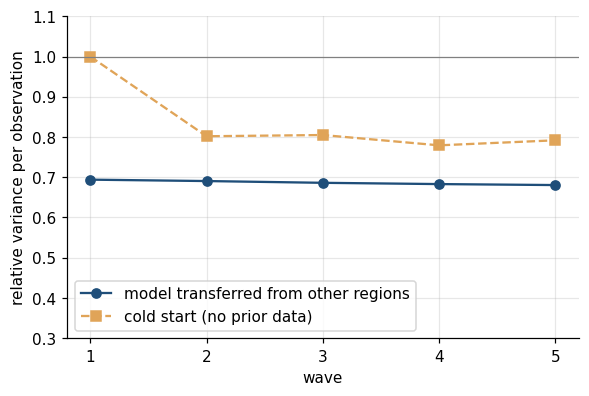

In [4]:
def trajectory(make_models, n_rep=100, size=100, waves=5, seed=0):
    rng = np.random.default_rng(seed)
    out = np.zeros((n_rep, waves))
    for r in range(n_rep):
        eng = E.ActiveEngine(make_models())
        for t in range(waves):
            units = eng.propose(size, rng)
            out[r, t] = eng.conditional_variance({"wc": y})["wc"] * size / y.var()
            eng.record({"wc": y[units]})
    return out.mean(axis=0)

X_cold = enriched(target, "wc").to_numpy()
warm = trajectory(lambda: [E.from_prior("wc", f0, classes)])
cold = trajectory(lambda: [E.cold_start("wc", X_cold)])

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(range(1, 6), warm, "o-", label="model transferred from other regions", color="#1f4e79")
ax.plot(range(1, 6), cold, "s--", label="cold start (no prior data)", color="#e0a458")
ax.axhline(1, color="grey", lw=0.8)
ax.set(xlabel="wave", ylabel="relative variance per observation", ylim=(0.3, 1.1), xticks=range(1, 6))
ax.legend()
fig.savefig("../reports/figures/waves.png", dpi=150, bbox_inches="tight")

## Benchmark on the held-out half

`scripts/run_benchmark.py` repeats this for the 16 map-region cases on the **test** half (never used
above), with 1,000 simulated campaigns per design. The engine is compared with simple random sampling,
stratification by map class (the usual good practice), the one-shot design based on the six indicators,
static designs that use the same error model as the engine and, without prior data, a two-phase design
(one uniform wave of 20%, one fit of the model, one stratified wave): does the loop beat a single update?

In [5]:
results = pd.read_csv("../reports/results/benchmark.csv")
table = 100 * results[results["n"] == 200].pivot_table(
    index="design", columns="scenario", values="saving", aggfunc="median")
table.round(1)

scenario,all,cold_start,new_product,transfer,transfer_no_embeddings
design,,,,,
class,6.9,NaN,NaN,NaN,NaN
class+diff,NaN,NaN,28.4,28.9,25.9
engine,NaN,17.5,32.0,32.8,30.4
importance,NaN,NaN,31.7,32.7,30.1
neyman,NaN,NaN,30.3,31.2,28.9
neyman+diff,NaN,NaN,32.1,33.1,31.0
one_shot_indicators,21.8,NaN,NaN,NaN,NaN
srs,0.0,NaN,NaN,NaN,NaN
srs+diff,NaN,NaN,27.3,28.8,26.4


scenario,transfer,transfer_no_embeddings,new_product,cold_start
classic (strata by map class),6.9,6.9,6.9,6.9
"best fixed design, same model",33.1,31.1,32.1,15.0
active loop (5 waves),32.8,30.4,32.0,17.5


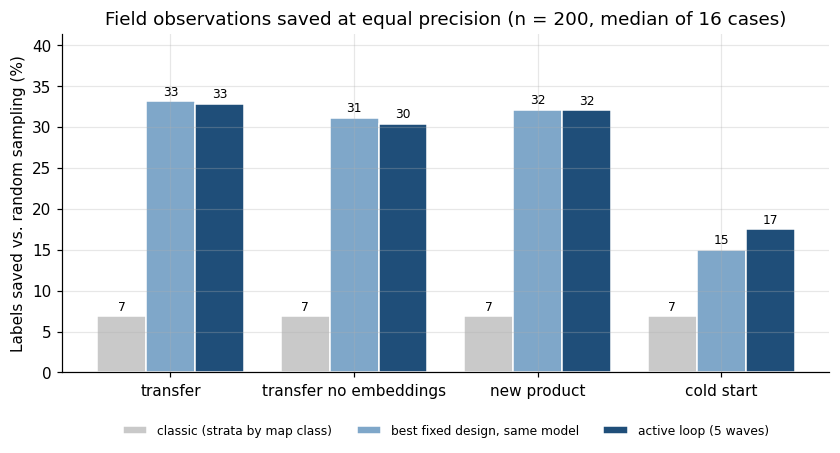

In [6]:
order = ["transfer", "transfer_no_embeddings", "new_product", "cold_start"]
r200 = results[results["n"] == 200]
# best fixed (non-iterative) design of each case; in cold start, the only one is the two-phase design
fixed = ["srs+diff", "importance", "neyman", "neyman+diff", "class+diff", "two_phase"]
best_fixed = (r200[r200["design"].isin(fixed)]
              .groupby(["scenario", "region", "product"])["saving"].max().groupby("scenario").median())
summary = pd.DataFrame({
    "classic (strata by map class)": 100 * r200[r200["design"] == "class"]["saving"].median(),
    "best fixed design, same model": 100 * best_fixed.reindex(order),
    "active loop (5 waves)": 100 * r200[r200["design"] == "engine"].groupby("scenario")["saving"].median().reindex(order),
}).T[order]

fig, ax = plt.subplots(figsize=(9, 4))
plots.savings_by_scenario(summary.fillna(0), ax)
ax.set_title("Field observations saved at equal precision (n = 200, median of 16 cases)")
fig.savefig("../reports/figures/savings.png", dpi=150, bbox_inches="tight")
summary.round(1)

### Are the confidence intervals valid?

In [7]:
designs = r200[r200["design"].isin(["engine", "two_phase"])]
designs.groupby(["design", "scenario"])[["coverage", "bias"]].agg(["min", "max"]).round(3)

coverage          bias       
                                      min    max    min    max
design    scenario                                            
engine    cold_start                0.937  0.958 -0.001  0.002
          new_product               0.932  0.953 -0.001  0.001
          transfer                  0.930  0.952 -0.002  0.002
          transfer_no_embeddings    0.930  0.961 -0.002  0.001
two_phase cold_start                0.938  0.956 -0.002  0.003

## What I take from this

- **A third fewer field observations** for the same precision when the error model is transferred from
  other regions (median 32.8% over 16 cases), and as much for a map never validated before (32.0%),
  against 6.9% for the usual stratification by map class.
- **Honest limit: with a good transferred model, the loop adds nothing measurable.** A fixed stratified
  design using the same model does as well (33.1% vs 32.8%; the loop is ahead in 5 cases out of 16),
  because error patterns transfer between these areas and the loop then only recalibrates the model.
  The gain comes from the information in the error model, which is why notebook 2 matters.
- **Without any prior data the loop saves 17.5%**, but a two-phase design (one random wave of 40, one
  fit of the model, one targeted wave of 160) already saves 15.0%. Iterating beats a single update in 12
  cases out of 16, by a median of 1.3 points: a real but small effect. Most of what the loop learns, it
  learns from the first wave (relative variance from 1 to about 0.8, then nearly flat).
- **The estimates stay valid**: coverage of the 95% intervals between 93% and 96%, bias at most 0.33 point,
  in every scenario.